# 📘 5.5 Evaluating Regression Performance

### Turning model scores into defensible engineering evidence

A model can fit, converge and produce plausible predictions while still being unsuitable
for its intended decision. Regression evaluation asks more than “which score is largest?”

We need a baseline, metrics with engineering meaning, data not used for fitting, residual
diagnostics, operating-region checks and an honest record of how the final model was
selected. No single number supplies all of that evidence.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* compare regression models with an explicit baseline;
* calculate and interpret MAE, MSE, RMSE and $R^2$;
* select metrics that match engineering consequences;
* use prediction-error and residual plots to diagnose model behaviour;
* compare performance across important operating regions;
* distinguish training, validation, cross-validation and final-test roles; and
* communicate performance, uncertainty and limitations without metric cherry-picking.

### 🔗 Unit Learning Outcome Alignment

This notebook supports **LO1, LO2 and LO3** through quantitative model comparison,
diagnostic evaluation and defensible engineering reporting.

### 📚 Sources used in this notebook

* scikit-learn — [Regression metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics)
* scikit-learn — [Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)
* scikit-learn — [DummyRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html)
* scikit-learn — [cross_validate](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html)
* NIST/SEMATECH — [How can I tell if a model fits my data?](https://www.itl.nist.gov/div898/handbook/pmd/section4/pmd44.htm)


## 📂 5.5.0 How to use this notebook

Run every code cell from top to bottom. No cell requires editing or typed input. The
notebook deliberately keeps a final test set untouched until model selection is complete.


## 📂 5.5.1 What does “good performance” mean?

Performance is conditional on a defined task:

* **what** quantity is predicted and in which units;
* **where** the model will operate;
* **which** errors create cost or risk;
* **when** the prediction is needed; and
* **what evidence** was independent of fitting and model selection.

A 5 kW error may be negligible for a large plant and unacceptable for a small component.
Underprediction and overprediction may also have different consequences.


In [ ]:
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

pd.set_option("display.precision", 4)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def regression_metrics(y_true, y_pred):
    return {
        "MAE_kW": mean_absolute_error(y_true, y_pred),
        "MSE_kW2": mean_squared_error(y_true, y_pred),
        "RMSE_kW": rmse(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


## 📂 5.5.2 Four common regression metrics

For residuals $e_i=y_i-\hat y_i$:

$$\mathrm{MAE}=\frac{1}{n}\sum|e_i|,$$

$$\mathrm{MSE}=\frac{1}{n}\sum e_i^2,$$

$$\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum e_i^2},$$

$$R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}.$$

MAE and RMSE retain the target units. MSE has squared units. $R^2$ is unitless and
compares squared error with a mean-prediction reference on the evaluated dataset.


### MAE and RMSE emphasise errors differently

Two models can have the same MAE but different RMSE. Squaring makes RMSE more sensitive
to occasional large deviations.


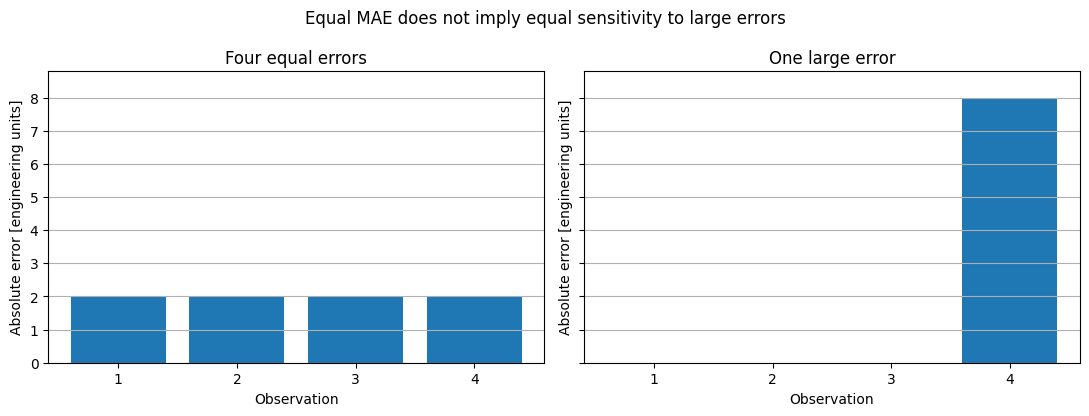

,MAE,RMSE,maximum_absolute_error
pattern,,,
Four equal errors,2.0,2.0,2.0
One large error,2.0,4.0,8.0


In [ ]:
error_patterns = {
    "Four equal errors": np.array([2.0, 2.0, 2.0, 2.0]),
    "One large error": np.array([0.0, 0.0, 0.0, 8.0]),
}
error_rows = []
for label, errors in error_patterns.items():
    error_rows.append({
        "pattern": label,
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors**2)),
        "maximum_absolute_error": np.max(np.abs(errors)),
    })
error_comparison = pd.DataFrame(error_rows).set_index("pattern")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (label, errors) in zip(axes, error_patterns.items()):
    ax.bar(np.arange(1, 5), errors)
    ax.set(xlabel="Observation", ylabel="Absolute error [engineering units]",
           title=label, xticks=np.arange(1, 5), ylim=(0, 8.8))
    ax.grid(True, axis="y")
fig.suptitle("Equal MAE does not imply equal sensitivity to large errors")
fig.tight_layout(); plt.show()
error_comparison


### 🧠 Metric interpretation

* Use **MAE** when typical absolute deviation is meaningful and errors should contribute
  approximately linearly.
* Use **RMSE** when larger errors deserve disproportionate emphasis.
* Use **MSE** when squared loss is needed mathematically, while remembering its units are
  squared.
* Use **R²** as a relative description of explained variation, not as an error tolerance.

A negative validation $R^2$ is possible: it means the model is worse under squared error
than predicting the evaluation-set mean for every observation.


## 📂 5.5.3 Percentage metrics need care

Mean absolute percentage error divides each absolute error by the corresponding target.
It is undefined at zero and can become enormous near zero. It also gives low-target
observations much greater relative influence.


In [ ]:
percentage_example = pd.DataFrame({
    "measured": [100.0, 10.0, 1.0, 0.01],
    "prediction": [105.0, 15.0, 6.0, 5.01],
})
percentage_example["absolute_error"] = np.abs(
    percentage_example.measured - percentage_example.prediction
)
percentage_example["absolute_percentage_error_percent"] = (
    100 * percentage_example.absolute_error / percentage_example.measured
)
percentage_example


,measured,prediction,absolute_error,absolute_percentage_error_percent
0,100.00,105.00,5.0,5.0
1,10.00,15.00,5.0,50.0
2,1.00,6.00,5.0,500.0
3,0.01,5.01,5.0,50000.0


Every row above has an absolute error of 5 units, but the percentage error ranges from
5% to 50,000%. Report the target range and do not use MAPE blindly when zero or very small
targets are possible.


## 📂 5.5.4 Engineering example: industrial-chiller power

We will predict chiller electrical power from cooling load, outdoor temperature and a
condenser-fouling index. Efficiency changes nonlinearly with load and temperature.

### ⚠️ Data note

The dataset is synthetic and deterministic. It is designed to resemble plausible trends,
not a certified chiller or a particular facility. The noise-free teaching function is
retained only to support diagnostic interpretation.


In [ ]:
rng = np.random.default_rng(5501)
n_samples = 600
cooling_load_kw = rng.uniform(70.0, 520.0, n_samples)
outdoor_temperature_c = rng.uniform(18.0, 43.0, n_samples)
fouling_index = rng.uniform(0.0, 1.0, n_samples)

load_fraction = cooling_load_kw / 520.0
coefficient_of_performance = (
    6.2
    - 0.085 * (outdoor_temperature_c - 24.0)
    - 1.25 * (load_fraction - 0.62) ** 2
    - 0.55 * fouling_index
)
coefficient_of_performance = np.clip(coefficient_of_performance, 2.4, None)
noise_free_power_kw = (
    cooling_load_kw / coefficient_of_performance
    + 7.0
    + 0.018 * np.maximum(outdoor_temperature_c - 26.0, 0.0) ** 2
)
noise_scale_kw = 1.8 + 0.018 * noise_free_power_kw
measured_power_kw = noise_free_power_kw + rng.normal(0.0, noise_scale_kw)

chiller_data = pd.DataFrame({
    "cooling_load_kw": cooling_load_kw,
    "outdoor_temperature_c": outdoor_temperature_c,
    "fouling_index": fouling_index,
    "measured_electrical_power_kw": measured_power_kw,
    "true_power_for_teaching_only_kw": noise_free_power_kw,
})
chiller_data.head(8)


,cooling_load_kw,outdoor_temperature_c,fouling_index,measured_electrical_power_kw,true_power_for_teaching_only_kw
0,387.4336,42.2024,0.0919,99.0762,96.2682
1,350.9050,39.1508,0.9202,86.0686,89.8224
2,107.3429,31.0570,0.0631,25.9413,27.5183
3,299.8539,29.9737,0.2322,63.9836,61.1939
4,88.1564,25.3028,0.2604,22.4751,22.4867
5,318.2496,39.0219,0.3859,79.8255,77.6096
6,138.3511,31.4841,0.2575,39.8407,33.8157
7,254.0455,23.7425,0.5067,54.3104,49.9013


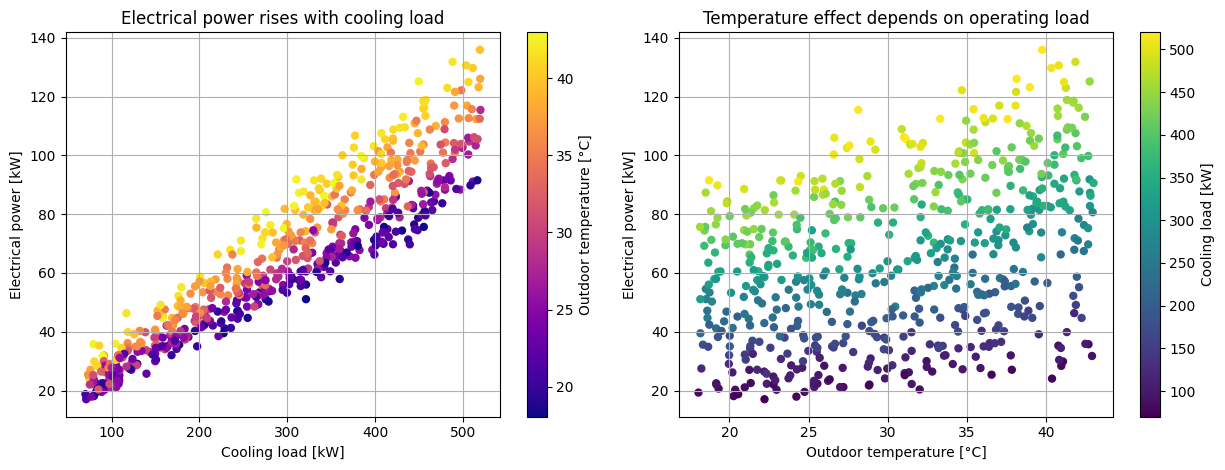

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
first = axes[0].scatter(
    chiller_data.cooling_load_kw,
    chiller_data.measured_electrical_power_kw,
    c=chiller_data.outdoor_temperature_c,
    cmap="plasma",
    s=25,
)
axes[0].set(xlabel="Cooling load [kW]", ylabel="Electrical power [kW]",
            title="Electrical power rises with cooling load")
fig.colorbar(first, ax=axes[0], label="Outdoor temperature [°C]")
second = axes[1].scatter(
    chiller_data.outdoor_temperature_c,
    chiller_data.measured_electrical_power_kw,
    c=chiller_data.cooling_load_kw,
    cmap="viridis",
    s=25,
)
axes[1].set(xlabel="Outdoor temperature [°C]", ylabel="Electrical power [kW]",
            title="Temperature effect depends on operating load")
fig.colorbar(second, ax=axes[1], label="Cooling load [kW]")
for ax in axes: ax.grid(True)
fig.tight_layout(); plt.show()


## 📂 5.5.5 Training, validation and final-test roles

* **Training data** estimate model parameters.
* **Validation data** compare methods and hyperparameters.
* **Test data** provide one final evaluation after choices are fixed.

If we repeatedly inspect test performance and adjust the model, the test set has become
another validation set. Its final score is then optimistic.


In [ ]:
features = ["cooling_load_kw", "outdoor_temperature_c", "fouling_index"]
X = chiller_data[features]
y = chiller_data["measured_electrical_power_kw"]

X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development, y_development, test_size=0.25, random_state=42
)

pd.DataFrame({
    "subset": ["training", "validation", "final test"],
    "samples": [len(X_train), len(X_validation), len(X_test)],
    "role": ["fit parameters", "select model", "final evaluation once"],
})


,subset,samples,role
0,training,360,fit parameters
1,validation,120,select model
2,final test,120,final evaluation once


## 📂 5.5.6 Start with a baseline

`DummyRegressor` ignores the features and applies a simple rule. A model that cannot
improve meaningfully on this reference has not demonstrated useful predictive skill.

We compare the four Week 5 model families using fixed, reasonable settings. The purpose
is evaluation, not exhaustive tuning.


In [ ]:
candidate_models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Decision tree": DecisionTreeRegressor(
        max_depth=6, min_samples_leaf=8, random_state=42
    ),
    "RBF SVR": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=100.0, epsilon=2.0, gamma=0.25),
    ),
    "Neural network": make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(20,),
            activation="relu",
            solver="adam",
            alpha=0.01,
            learning_rate_init=0.01,
            max_iter=2000,
            early_stopping=True,
            n_iter_no_change=30,
            random_state=42,
        ),
    ),
}

validation_rows = []
fitted_candidates = {}
for name, model in candidate_models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_validation)
    fitted_candidates[name] = model
    validation_rows.append({
        "model": name,
        **regression_metrics(y_validation, prediction),
    })

validation_results = (
    pd.DataFrame(validation_rows)
    .set_index("model")
    .sort_values("RMSE_kW")
)
validation_results


,MAE_kW,MSE_kW2,RMSE_kW,R2
model,,,,
RBF SVR,2.6709,11.0337,3.3217,0.9848
Neural network,3.2762,15.8991,3.9874,0.9782
Linear regression,3.7843,22.6579,4.7600,0.9689
Decision tree,4.9032,42.9388,6.5528,0.9410
Mean baseline,22.5983,740.4462,27.2111,-0.0169


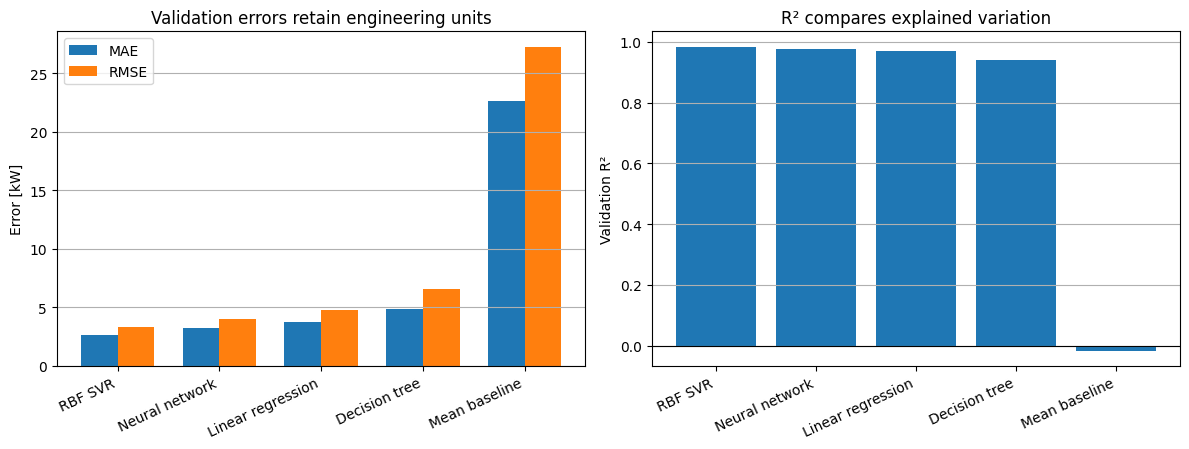

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
order = validation_results.index
x = np.arange(len(order)); width = 0.36
axes[0].bar(x - width/2, validation_results.loc[order, "MAE_kW"], width, label="MAE")
axes[0].bar(x + width/2, validation_results.loc[order, "RMSE_kW"], width, label="RMSE")
axes[0].set(ylabel="Error [kW]", title="Validation errors retain engineering units")
axes[0].set_xticks(x, order, rotation=25, ha="right"); axes[0].legend()
axes[1].bar(order, validation_results.loc[order, "R2"])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(ylabel="Validation R²", title="R² compares explained variation")
axes[1].tick_params(axis="x", rotation=25)
for label in axes[1].get_xticklabels(): label.set_ha("right")
for ax in axes: ax.grid(True, axis="y")
fig.tight_layout(); plt.show()


### Visualising each candidate solution

Metric bars compare numerical performance but do not show what each model has learned.
We therefore plot a common two-feature slice with the fouling index fixed at 0.5. Every
panel uses the same axes and colour scale, so shapes and power levels can be compared
directly.


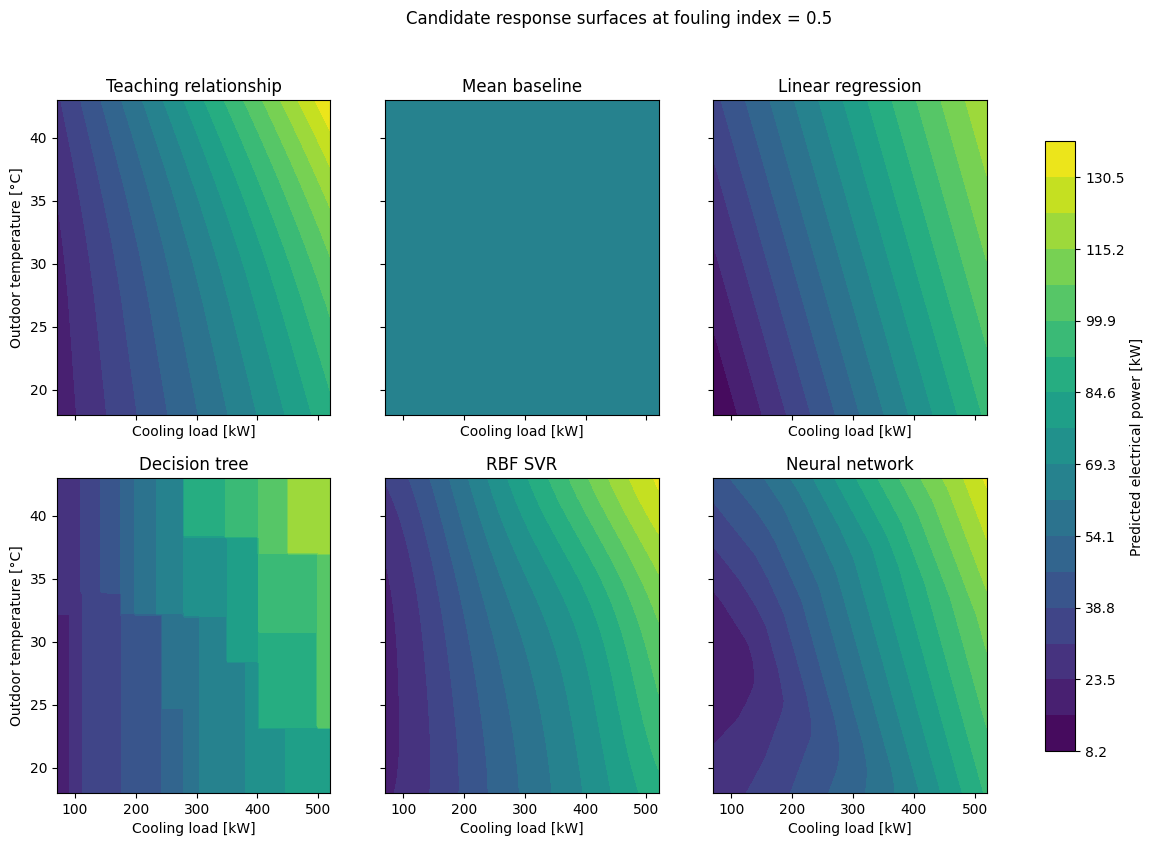

In [ ]:
load_axis = np.linspace(70.0, 520.0, 140)
temperature_axis = np.linspace(18.0, 43.0, 120)
load_surface, temperature_surface = np.meshgrid(load_axis, temperature_axis)
fixed_fouling = 0.5

surface_queries = pd.DataFrame({
    "cooling_load_kw": load_surface.ravel(),
    "outdoor_temperature_c": temperature_surface.ravel(),
    "fouling_index": fixed_fouling,
})
surface_load_fraction = load_surface / 520.0
surface_cop = (
    6.2
    - 0.085 * (temperature_surface - 24.0)
    - 1.25 * (surface_load_fraction - 0.62) ** 2
    - 0.55 * fixed_fouling
)
surface_cop = np.clip(surface_cop, 2.4, None)
teaching_surface = (
    load_surface / surface_cop
    + 7.0
    + 0.018 * np.maximum(temperature_surface - 26.0, 0.0) ** 2
)

surfaces = {"Teaching relationship": teaching_surface}
for name, model in fitted_candidates.items():
    surfaces[name] = model.predict(surface_queries).reshape(load_surface.shape)

colour_min = min(surface.min() for surface in surfaces.values())
colour_max = max(surface.max() for surface in surfaces.values())
levels = np.linspace(colour_min, colour_max, 18)

fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for ax, (name, surface) in zip(axes.ravel(), surfaces.items()):
    contour = ax.contourf(
        load_surface,
        temperature_surface,
        surface,
        levels=levels,
        cmap="viridis",
    )
    ax.set_title(name)
    ax.set_xlabel("Cooling load [kW]")
for ax in axes[:, 0]:
    ax.set_ylabel("Outdoor temperature [°C]")
fig.colorbar(contour, ax=axes, shrink=0.88, label="Predicted electrical power [kW]")
fig.suptitle("Candidate response surfaces at fouling index = 0.5")
plt.show()


### 🧠 Reading the model surfaces

* The **mean baseline** is one flat colour because it ignores every feature.
* **Linear regression** produces a smooth plane and cannot represent changing curvature.
* The **decision tree** creates rectangular, piecewise-constant regions.
* **RBF SVR** produces a smooth nonlinear surface supported by local similarities.
* The **neural network** produces a smooth piecewise-linear approximation through its
  ReLU hidden neurons.

Similar overall metrics can conceal very different response shapes. The surface should
be checked against engineering expectations before selecting a model.


### 🧠 Reading the comparison

The baseline anchors the scale of the problem. MAE describes typical error; RMSE reveals
the additional influence of large errors; $R^2$ describes improvement relative to a mean
reference. Model ranking can change with the metric, so the primary metric should be
chosen before looking for the winner.


## 📂 5.5.7 Residuals reveal what an average hides

We define residual as

$$e=y-\hat y.$$

A positive residual means the model **underpredicted** electrical power. A negative
residual means it overpredicted. NIST cautions that a high $R^2$ does not guarantee an
adequate model; graphical residual analysis is a primary diagnostic tool.


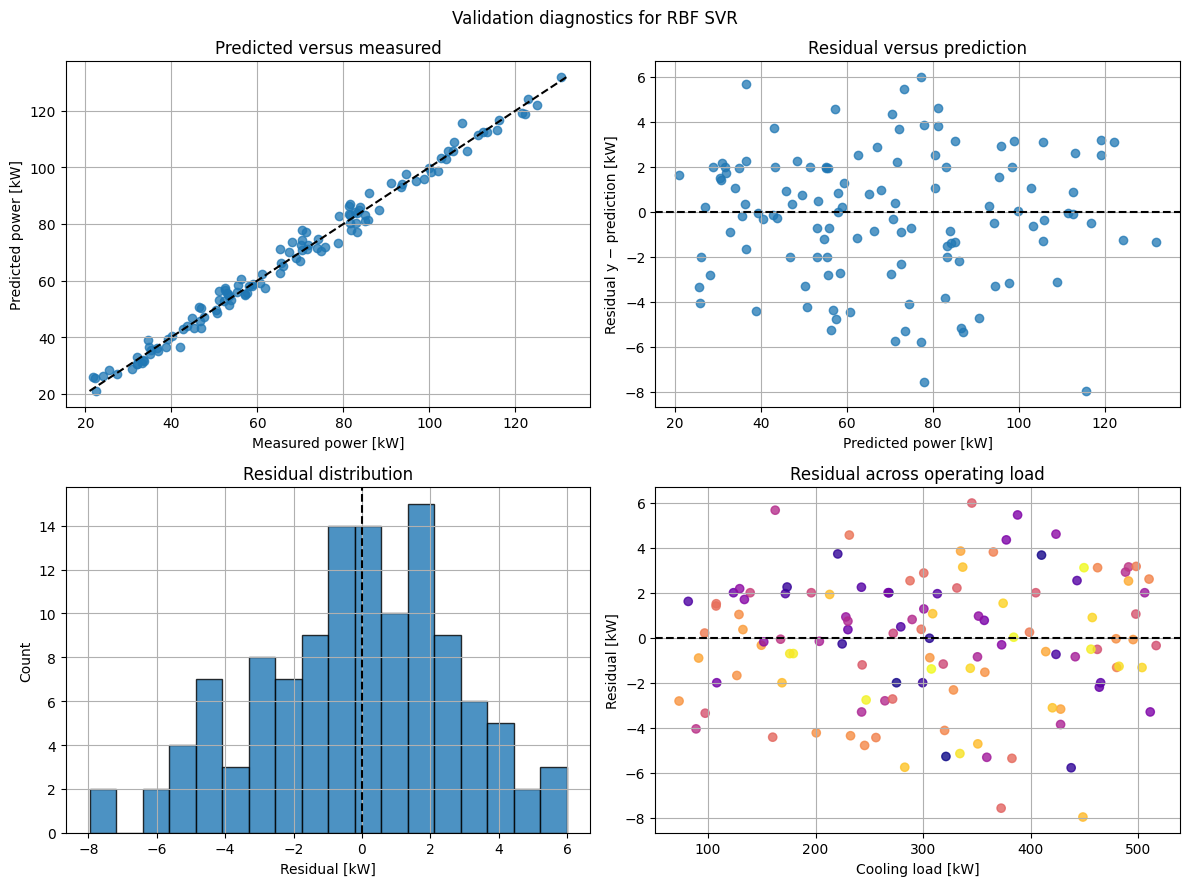

In [ ]:
selected_name = validation_results.index[0]
selected_model = fitted_candidates[selected_name]
selected_validation_prediction = selected_model.predict(X_validation)
validation_residual = y_validation.to_numpy() - selected_validation_prediction

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].scatter(y_validation, selected_validation_prediction, alpha=0.75)
identity_limits = [min(y_validation.min(), selected_validation_prediction.min()),
                   max(y_validation.max(), selected_validation_prediction.max())]
axes[0, 0].plot(identity_limits, identity_limits, "--", color="black")
axes[0, 0].set(xlabel="Measured power [kW]", ylabel="Predicted power [kW]",
               title="Predicted versus measured")

axes[0, 1].scatter(selected_validation_prediction, validation_residual, alpha=0.75)
axes[0, 1].axhline(0, linestyle="--", color="black")
axes[0, 1].set(xlabel="Predicted power [kW]", ylabel="Residual y − prediction [kW]",
               title="Residual versus prediction")

axes[1, 0].hist(validation_residual, bins=18, edgecolor="black", alpha=0.8)
axes[1, 0].axvline(0, linestyle="--", color="black")
axes[1, 0].set(xlabel="Residual [kW]", ylabel="Count", title="Residual distribution")

axes[1, 1].scatter(X_validation.cooling_load_kw, validation_residual,
                   c=X_validation.outdoor_temperature_c, cmap="plasma", alpha=0.8)
axes[1, 1].axhline(0, linestyle="--", color="black")
axes[1, 1].set(xlabel="Cooling load [kW]", ylabel="Residual [kW]",
               title="Residual across operating load")
for ax in axes.ravel(): ax.grid(True)
fig.suptitle(f"Validation diagnostics for {selected_name}")
fig.tight_layout(); plt.show()


### What patterns matter?

Look for curvature, changing spread, clusters, bias and isolated large errors. Random
scatter around zero is encouraging but not proof of deployment reliability. Residuals
should also be checked against time, equipment identity and other relevant variables when
those data exist.


## 📂 5.5.8 Evaluate important operating regions

An overall metric weights observations according to their frequency in the evaluation
set. A rare but safety-critical region can therefore be hidden. We divide validation
observations into cooling-load bands and report error separately.


In [ ]:
regional_evaluation = X_validation.copy()
regional_evaluation["measured_power_kw"] = y_validation
regional_evaluation["prediction_kw"] = selected_validation_prediction
regional_evaluation["residual_kw"] = validation_residual
regional_evaluation["absolute_error_kw"] = np.abs(validation_residual)
regional_evaluation["load_region"] = pd.cut(
    regional_evaluation.cooling_load_kw,
    bins=[0, 220, 380, np.inf],
    labels=["low load", "medium load", "high load"],
)

regional_summary = regional_evaluation.groupby(
    "load_region", observed=False
).agg(
    samples=("absolute_error_kw", "size"),
    MAE_kW=("absolute_error_kw", "mean"),
    mean_residual_kW=("residual_kw", "mean"),
    maximum_underprediction_kW=("residual_kw", "max"),
)
regional_summary


,samples,MAE_kW,mean_residual_kW,maximum_underprediction_kW
load_region,,,,
low load,30,2.0599,-0.1819,5.5562
medium load,53,2.8695,-0.4218,5.1873
high load,37,2.8817,0.0001,6.8273


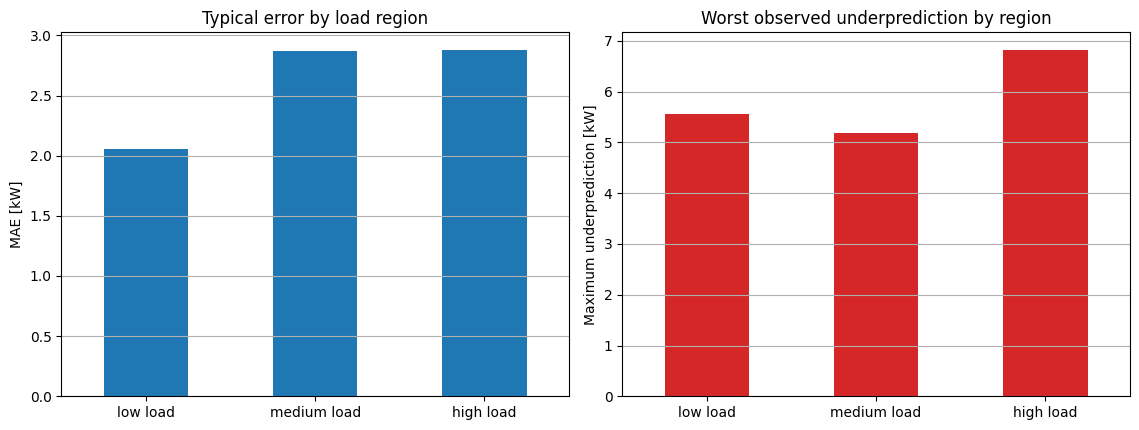

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
regional_summary.MAE_kW.plot.bar(ax=axes[0], color="tab:blue")
axes[0].set(ylabel="MAE [kW]", xlabel="", title="Typical error by load region")
regional_summary.maximum_underprediction_kW.plot.bar(ax=axes[1], color="tab:red")
axes[1].set(ylabel="Maximum underprediction [kW]", xlabel="",
            title="Worst observed underprediction by region")
for ax in axes:
    ax.grid(True, axis="y"); ax.tick_params(axis="x", rotation=0)
fig.tight_layout(); plt.show()


### ⚠️ Direction matters

MAE and RMSE discard error direction. If underpredicting electrical demand risks
undersizing supply or exceeding a limit, also report signed residual summaries and a
consequence-specific threshold. The threshold must come from the engineering context,
not from whichever value makes a model look favourable.


## 📂 5.5.9 Cross-validation measures split sensitivity

A single validation result depends on one random split. Five-fold cross-validation fits
five models: each fold is used once for validation and the other four folds for training.
The final test set remains excluded.

Preprocessing stays inside each pipeline so every scaler is fitted only on that fold's
training portion.


In [ ]:
comparison_names = list(validation_results.index[:3])
cross_validation = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}
cv_rows = []
for name in comparison_names:
    result = cross_validate(
        candidate_models[name],
        X_development,
        y_development,
        cv=cross_validation,
        scoring=scoring,
        return_train_score=False,
    )
    for fold in range(5):
        cv_rows.append({
            "model": name,
            "fold": fold + 1,
            "MAE_kW": -result["test_MAE"][fold],
            "RMSE_kW": -result["test_RMSE"][fold],
            "R2": result["test_R2"][fold],
        })
cv_results = pd.DataFrame(cv_rows)
cv_summary = cv_results.groupby("model").agg(
    mean_RMSE_kW=("RMSE_kW", "mean"),
    std_RMSE_kW=("RMSE_kW", "std"),
    mean_MAE_kW=("MAE_kW", "mean"),
    mean_R2=("R2", "mean"),
).sort_values("mean_RMSE_kW")
cv_summary


,mean_RMSE_kW,std_RMSE_kW,mean_MAE_kW,mean_R2
model,,,,
RBF SVR,3.4787,0.3006,2.7558,0.9833
Neural network,4.1952,0.6575,3.3937,0.9753
Linear regression,4.7800,0.3439,3.8151,0.9685


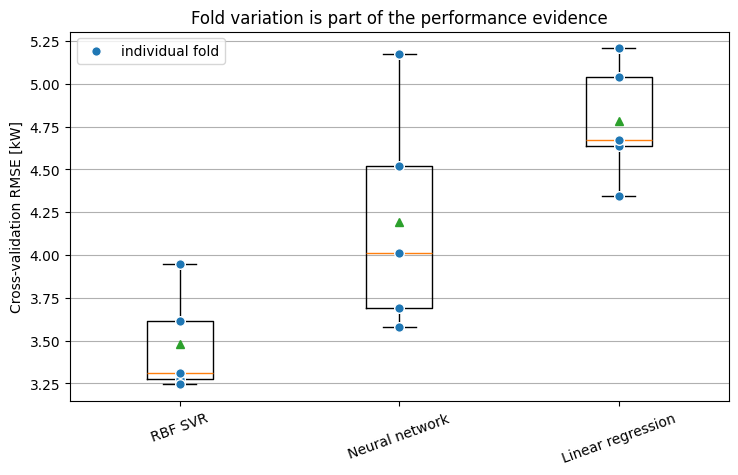

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
box_data = [
    cv_results.loc[cv_results.model == name, "RMSE_kW"]
    for name in cv_summary.index
]
ax.boxplot(box_data, tick_labels=cv_summary.index, showmeans=True)
for position, name in enumerate(cv_summary.index, start=1):
    fold_values = cv_results.loc[cv_results.model == name, "RMSE_kW"].to_numpy()
    ax.scatter(
        np.full(fold_values.size, position),
        fold_values,
        color="tab:blue",
        edgecolor="white",
        s=48,
        zorder=3,
        label="individual fold" if position == 1 else None,
    )
ax.set(ylabel="Cross-validation RMSE [kW]",
       title="Fold variation is part of the performance evidence")
ax.tick_params(axis="x", rotation=20)
ax.grid(True, axis="y"); ax.legend(); plt.show()


### 🧠 How to read the cross-validation figure

Each model has **five blue points**, one RMSE from each validation fold. Lower values are
better.

* The line inside the box is the **median** fold RMSE.
* The box spans the middle 50% of fold values.
* The whiskers extend across the remaining non-outlying values.
* The green triangle is the **mean** fold RMSE.
* A narrow vertical spread means performance changed little across these folds; a wide
  spread means the reported result was more sensitive to which samples were held out.

With only five folds, the individual points are more informative than treating the box as
a precise distribution. Here the RBF SVR has both the lowest typical RMSE and a relatively
small fold-to-fold spread.

### What cross-validation does and does not show

Fold variation shows sensitivity to these particular resamples. It is not a confidence
interval for every future deployment condition. Random K-fold is also inappropriate when
time order, repeated equipment or grouped experiments create dependence; Notebook 5.6
develops split selection in detail.


## 📂 5.5.10 Final model and one-time test evaluation

We fix the selected method using validation and cross-validation evidence, refit it on
all development data, and evaluate the untouched test set once. We do not return to tune
the model after seeing this result.


In [ ]:
final_name = cv_summary.index[0]
final_model = candidate_models[final_name]
final_model.fit(X_development, y_development)
final_test_prediction = final_model.predict(X_test)
final_test_metrics = pd.Series(
    regression_metrics(y_test, final_test_prediction),
    name=f"Final test: {final_name}",
)
final_test_metrics


,Final test: RBF SVR
MAE_kW,2.3427
MSE_kW2,9.4606
RMSE_kW,3.0758
R2,0.9836


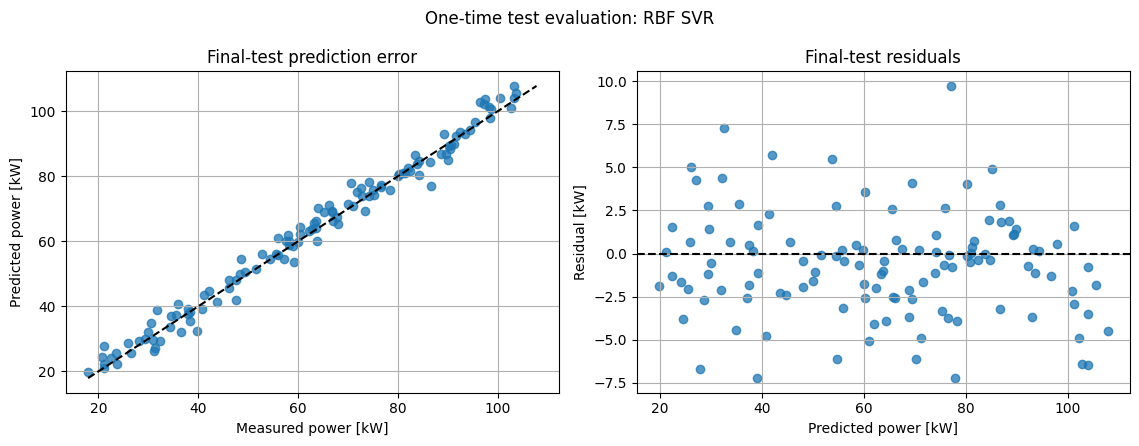

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
test_residual = y_test.to_numpy() - final_test_prediction
axes[0].scatter(y_test, final_test_prediction, alpha=0.75)
limits = [min(y_test.min(), final_test_prediction.min()),
          max(y_test.max(), final_test_prediction.max())]
axes[0].plot(limits, limits, "--", color="black")
axes[0].set(xlabel="Measured power [kW]", ylabel="Predicted power [kW]",
            title="Final-test prediction error")
axes[1].scatter(final_test_prediction, test_residual, alpha=0.75)
axes[1].axhline(0, linestyle="--", color="black")
axes[1].set(xlabel="Predicted power [kW]", ylabel="Residual [kW]",
            title="Final-test residuals")
for ax in axes: ax.grid(True)
fig.suptitle(f"One-time test evaluation: {final_name}")
fig.tight_layout(); plt.show()


## 📂 5.5.11 Optional extension: how precise is the reported test MAE?

The final test MAE is about 2.34 kW, but it was calculated from 120 test observations. If
a different set of 120 comparable operating observations had been sampled, the average
error would not be exactly the same. A single test metric does not show that sampling
variation.

A simple **bootstrap** repeatedly resamples the 120 observed absolute test errors, with
replacement, and recalculates MAE. The resulting distribution answers a limited question:

> How much might the reported MAE vary because this finite test sample contains a
> particular collection of errors?

This conditional interval treats the fitted model and test observations as given. It does
not include every source of uncertainty, such as retraining variability, sensor bias or
deployment shift. It is also **not a prediction interval** for an individual future
observation.

### Why this differs from Section 5.5.9

* Cross-validation repeatedly **refits models** on different development folds and helps
  compare model-selection stability.
* This bootstrap keeps the **final fitted model fixed** and explores the sampling
  precision of one reported test metric.

This is an optional extension rather than a required step for every small project. Its
purpose is to prevent false precision such as treating 2.3427 kW as an exact property of
the model.


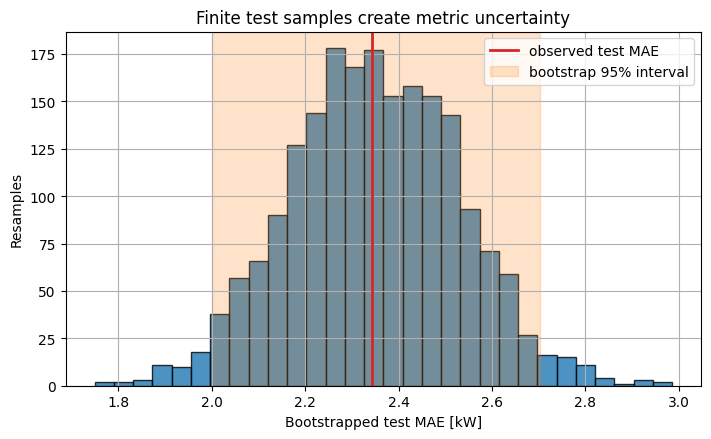

,0
test_MAE_kW,2.3427
bootstrap_lower_kW,2.0010
bootstrap_upper_kW,2.7022


In [ ]:
rng_bootstrap = np.random.default_rng(5511)
absolute_test_errors = np.abs(test_residual)
bootstrap_mae = np.array([
    rng_bootstrap.choice(
        absolute_test_errors,
        size=len(absolute_test_errors),
        replace=True,
    ).mean()
    for _ in range(2000)
])
interval = np.quantile(bootstrap_mae, [0.025, 0.975])

fig, ax = plt.subplots(figsize=(8.2, 4.6))
ax.hist(bootstrap_mae, bins=30, edgecolor="black", alpha=0.8)
ax.axvline(absolute_test_errors.mean(), color="tab:red", linewidth=2,
           label="observed test MAE")
ax.axvspan(interval[0], interval[1], color="tab:orange", alpha=0.22,
           label="bootstrap 95% interval")
ax.set(xlabel="Bootstrapped test MAE [kW]", ylabel="Resamples",
       title="Finite test samples create metric uncertainty")
ax.grid(True); ax.legend(); plt.show()

pd.Series({"test_MAE_kW": absolute_test_errors.mean(),
           "bootstrap_lower_kW": interval[0],
           "bootstrap_upper_kW": interval[1]})


## 📂 5.5.12 Reporting checklist

A defensible regression-performance report should state:

1. target, units, operating domain and intended decision;
2. data provenance and splitting strategy;
3. baseline and candidate models;
4. primary metric chosen from engineering consequences;
5. supporting metrics in target units;
6. residual and prediction-error diagnostics;
7. important regional and directional errors;
8. cross-validation mean and spread where appropriate;
9. one-time final-test result;
10. uncertainty, limitations and unsupported conditions.

Report the complete planned metric set for every candidate. Selecting only the metric
that favours a preferred model is metric cherry-picking.


## 📂 5.5.13 Useful packages and functions

| Item | Purpose | Important caution |
|---|---|---|
| `DummyRegressor` | Establish a simple baseline | Does not use feature relationships |
| `mean_absolute_error` | Typical absolute error | Hides direction and rare maxima |
| `mean_squared_error` | Mean squared error | Has squared target units |
| square root of MSE | RMSE in target units | Emphasises larger errors |
| `r2_score` | Relative explained variation | Can be negative; does not express tolerance |
| `mean_absolute_percentage_error` | Relative absolute error | Unstable near zero |
| `cross_validate` | Evaluate multiple metrics across folds | Split strategy must match data structure |
| `KFold` | Create repeated train/validation roles | Random folds may leak groups or time |
| residual plots | Diagnose patterns and regions | Visual evidence complements metrics |
| bootstrap resampling | Explore finite-sample metric variation | Not complete deployment uncertainty |


## 📂 5.5.14 Engineering workflow and summary

Start with the decision and consequences, not a favourite metric. Reserve independent
evidence, establish a baseline, compare a predeclared metric set, inspect residuals,
examine important operating regions and quantify split sensitivity. Select the model
using development evidence, then evaluate the final test set once.

A model is not defensible because it has a high $R^2$ or the smallest average error in one
table. Defensible performance is a coherent body of evidence tied to intended use.


## 📚 References

* scikit-learn developers, *Metrics and Scoring: Regression Metrics*.
* scikit-learn developers, *Cross-validation: Evaluating Estimator Performance*.
* scikit-learn developers, *DummyRegressor* and *cross_validate* documentation.
* NIST/SEMATECH, *How Can I Tell if a Model Fits My Data?*

## 🤖 AI Acknowledgment

Generative AI was used to help structure explanations, develop teaching examples and
review code. The teaching team remains responsible for the mathematical content,
engineering interpretation, source selection and final notebook.
